# Procurement Collusion Detection

Detecting bid-rigging networks in public procurement with graph analytics and anomaly detection. Each part builds on the previous one.

1. Graph construction
2. Co-bidding network


## Part 1. Graph Construction

Building a heterogeneous procurement network from companies, contracts and beneficial owners, and taking a first look at its structure.

### Load and sanity-check the data

In [11]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/input/datasets/princeamofa/procurement-synthetic"

companies = pd.read_csv(f"{DATA_DIR}/companies.csv", parse_dates=["registration_date"])
bids = pd.read_csv(f"{DATA_DIR}/bids.csv", parse_dates=["submission_timestamp"])

print("companies:", companies.shape, "| bids:", bids.shape)
print("missing values:", companies.isna().sum().sum(), bids.isna().sum().sum())
print("contracts:", bids["contract_id"].nunique(), "| active bidders:", bids["company_id"].nunique())

bids_per_contract = bids.groupby("contract_id").size()
print(bids_per_contract.describe().round(2))
print(f"single-bidder contracts: {(bids_per_contract == 1).mean():.1%}")

companies: (500, 6) | bids: (5000, 7)
missing values: 0 0
contracts: 1252 | active bidders: 500
count    1252.00
mean        3.99
std         1.73
min         1.00
25%         3.00
50%         4.00
75%         5.00
max        10.00
dtype: float64
single-bidder contracts: 5.4%


### Build the heterogeneous graph

Three node types (company, contract, owner) and two edge types (bid, owns). Bids are also expressed as a ratio of contract value so tenders of different sizes are comparable.

In [12]:
bids["bid_ratio"] = bids["bid_amount"] / bids["contract_value"]

G = nx.Graph()

for r in companies.itertuples(index=False):
    G.add_node(r.company_id, node_type="company", sector=r.sector,
               registration_date=r.registration_date, risk_flag=r.risk_flag)

for owner in companies["ultimate_beneficial_owner_id"].unique():
    G.add_node(owner, node_type="owner")
G.add_edges_from(
    ((r.company_id, r.ultimate_beneficial_owner_id) for r in companies.itertuples(index=False)),
    edge_type="owns",
)

contracts = bids.groupby("contract_id").agg(
    contract_value=("contract_value", "first"),
    n_bidders=("bid_id", "count"),
)
for cid, r in contracts.iterrows():
    G.add_node(cid, node_type="contract", contract_value=r.contract_value,
               n_bidders=int(r.n_bidders))

for r in bids.itertuples(index=False):
    G.add_edge(r.company_id, r.contract_id, edge_type="bid",
               bid_amount=r.bid_amount, bid_ratio=r.bid_ratio,
               won=r.winning_status, ts=r.submission_timestamp)

print(G)
print(pd.Series(nx.get_node_attributes(G, "node_type")).value_counts())
print(pd.Series(nx.get_edge_attributes(G, "edge_type")).value_counts())

Graph with 2206 nodes and 5500 edges
contract    1252
company      500
owner        454
Name: count, dtype: int64
bid     5000
owns     500
Name: count, dtype: int64


### Is the network connected?

In [13]:
components = list(nx.connected_components(G))
print(f"connected components: {len(components)}")
print(f"largest component: {max(len(c) for c in components):,} of {G.number_of_nodes():,} nodes")

connected components: 1
largest component: 2,206 of 2,206 nodes


### Shared ownership: a lead, not a verdict

In [14]:
owner_sizes = companies.groupby("ultimate_beneficial_owner_id")["company_id"].nunique()
shared = owner_sizes[owner_sizes > 1]
print(f"owners controlling more than one firm: {len(shared)}")
print(shared.value_counts().sort_index().rename("number of owners"))

owners controlling more than one firm: 18
company_id
2    5
3    5
4    3
5    3
6    2
Name: number of owners, dtype: int64


### Key takeaways

- The network has **2,206 nodes** (500 companies, 1,252 contracts, 454 owners) and **5,500 edges** (5,000 bids, 500 ownership links), forming a single connected structure.
- Competition looks healthy on the surface: a median of 4 bidders per contract and only 5.4% single-bidder tenders. Bid rigging would not show up in these headline figures, which is why the analysis has to go below contract level.
- **18 owners control more than one firm**, in groups of 2 to 6. Group size alone does not distinguish a family business from a cartel, so shared ownership is treated as a lead to investigate rather than evidence.

**Next:** project this graph into a company-to-company co-bidding network and measure how often linked firms bid on the same tenders and how closely their prices move together.

## Part 2. Co-bidding Network

Collapsing the company to contract graph into a company to company network, where two firms are linked if they ever bid on the same tender, and describing each link by how often they meet, how close their prices are and how close together they submit.

### Every pair of firms that met on a tender

Joining bids to themselves on `contract_id` gives one row per pair of firms per shared tender. For each meeting we measure the relative price gap between their bids and the time between their submissions.

In [16]:
cols = ["contract_id", "company_id", "bid_amount", "submission_timestamp"]
pairs = bids[cols].merge(bids[cols], on="contract_id", suffixes=("_a", "_b"))
pairs = pairs[pairs["company_id_a"] < pairs["company_id_b"]]   # each pair once, no self-pairs

pairs["price_gap"] = (pairs["bid_amount_a"] - pairs["bid_amount_b"]).abs() \
                     / pairs[["bid_amount_a", "bid_amount_b"]].min(axis=1)
pairs["time_gap_min"] = (pairs["submission_timestamp_a"]
                         - pairs["submission_timestamp_b"]).abs().dt.total_seconds() / 60

print("pairwise meetings:", len(pairs))

pairwise meetings: 9357


### One edge per pair of firms

Aggregating the meetings gives the co-bidding network. Each edge carries four behavioural signals plus whether the two firms share an owner.

In [17]:
edges = pairs.groupby(["company_id_a", "company_id_b"]).agg(
    shared_contracts=("contract_id", "count"),
    median_price_gap=("price_gap", "median"),
    median_time_gap_min=("time_gap_min", "median"),
).reset_index()

n_bids = bids.groupby("company_id").size()
edges["jaccard"] = edges["shared_contracts"] / (
    edges["company_id_a"].map(n_bids) + edges["company_id_b"].map(n_bids) - edges["shared_contracts"]
)

owner = companies.set_index("company_id")["ultimate_beneficial_owner_id"]
edges["same_owner"] = (edges["company_id_a"].map(owner)
                       == edges["company_id_b"].map(owner)).astype(int)

print("company pairs that ever met:", len(edges))
print(edges["shared_contracts"].value_counts().sort_index())

company pairs that ever met: 7276
shared_contracts
1     5960
2     1049
3      185
4       34
5        8
6        2
11       5
12       7
13       5
14       1
16       9
17       6
18       3
19       2
Name: count, dtype: int64


### The pairs that meet most often

In [18]:
edges.sort_values("shared_contracts", ascending=False).head(20).round(4)

,company_id_a,company_id_b,shared_contracts,median_price_gap,median_time_gap_min,jaccard,same_owner
1926,CMP0070,CMP0319,19,0.0070,7.8500,0.3455,1
1158,CMP0040,CMP0293,19,0.0065,6.8167,0.4318,1
5638,CMP0269,CMP0293,18,0.0060,4.0583,0.4500,1
1923,CMP0070,CMP0293,18,0.0059,7.7500,0.3396,1
1160,CMP0040,CMP0319,18,0.0089,7.4083,0.3750,1
1141,CMP0040,CMP0070,17,0.0048,8.2167,0.3333,1
1155,CMP0040,CMP0269,17,0.0042,7.6833,0.4474,1
5639,CMP0269,CMP0319,17,0.0081,6.5167,0.3864,1
1350,CMP0046,CMP0410,17,0.0067,9.0333,0.5152,1
1919,CMP0070,CMP0269,17,0.0048,8.0333,0.3696,1


### Frequency against price similarity

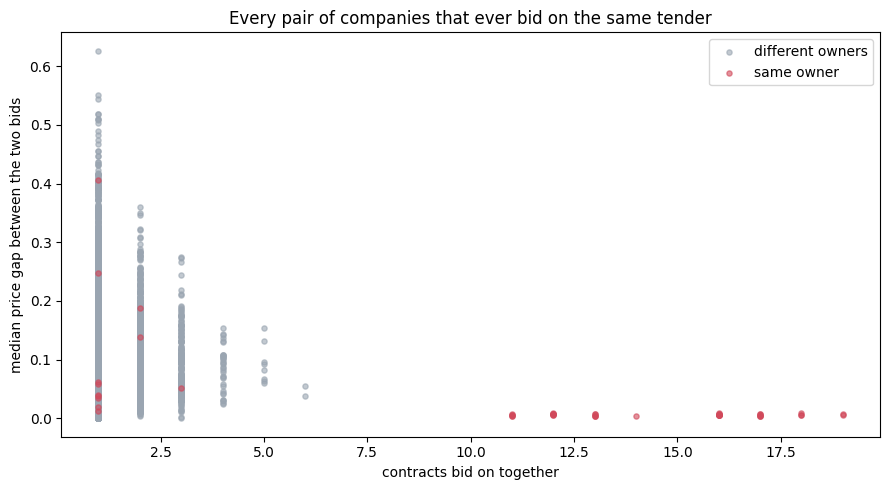

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
for flag, label, color in [(0, "different owners", "#9aa5b1"), (1, "same owner", "#d1495b")]:
    sub = edges[edges["same_owner"] == flag]
    ax.scatter(sub["shared_contracts"], sub["median_price_gap"],
               s=14, alpha=0.6, label=label, color=color)
ax.set_xlabel("contracts bid on together")
ax.set_ylabel("median price gap between the two bids")
ax.set_title("Every pair of companies that ever bid on the same tender")
ax.legend()
plt.tight_layout()
plt.show()

### Typical meetings against frequent ones

In [20]:
frequent = edges["shared_contracts"] >= 10
summary = edges.groupby(frequent.map({True: "meet 10+ times", False: "meet under 10 times"})).agg(
    pairs=("shared_contracts", "count"),
    share_same_owner=("same_owner", "mean"),
    median_price_gap=("median_price_gap", "median"),
    median_time_gap_hours=("median_time_gap_min", lambda s: s.median() / 60),
).rename_axis("pair type").round(3)
summary

,pairs,share_same_owner,median_price_gap,median_time_gap_hours
pair type,,,,
meet 10+ times,38,1.000,0.006,0.111
meet under 10 times,7238,0.002,0.090,186.108


### Key takeaways

- About 9,400 pairwise meetings collapse into roughly 7,300 company pairs. Most pairs meet once or twice, which is what open competition looks like.
- A small group of 38 pairs meets 11 times or more. These pairs price within about 1% of each other and submit within minutes, while typical pairs are about 9% apart on price and roughly 8 days apart in time.
- All 38 frequent pairs share an owner, but ownership on its own is a poor filter: the data holds 98 same-owner pairs, so flagging by ownership would also catch 60 honest pairs. The behavioural signals are what separate the two.
- **Caveat:** in this synthetic market honest firms rarely meet more than 6 times, because each sector has 40 to 100 firms. In thin real markets, honest suppliers can meet on almost every tender, so frequency alone would produce false positives. A thin-market stress test is planned later in the project.

**Next:** turn these signals into company-level red-flag features (win rotation, price clustering, submission bursts, registration timing) for anomaly scoring.